# Entraînement du modèle « bon état / endommagé »

Premier modèle de la version 2. Il répond à une seule question : **la pièce est-elle endommagée ?**

Données : `data/v2/` (voir `preparation_donnees_v2.ipynb`). Modèle : ResNet18 préentraîné sur ImageNet, comme en version 1.

Sections :
1. chargement des données;
2. entraînement (environ 10 minutes);
3. évaluation sur le jeu de test, au global et par source;
4. erreurs du modèle;
5. zones utilisées par le modèle (Grad-CAM);
6. test sur les photos réelles.

Cliquez sur **Run All**.

In [1]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image, ImageOps
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_score, recall_score
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DONNEES = RACINE / "data" / "v2"
CHEMIN_MODELE = RACINE / "modeles" / "v2_etat_resnet18.pt"
DOSSIER_RESULTATS = RACINE / "resultats"
GRAINE = 42
EPOQUES = 6

torch.manual_seed(GRAINE)
random.seed(GRAINE)
plt.rcParams["figure.dpi"] = 110
NOMS = {"bon_etat": "Bon état", "endommage": "Endommagé"}
print("PyTorch", torch.__version__)

PyTorch 2.15.0+cpu


## 1. Chargement des données

L'augmentation de données prépare le modèle à de vraies photos : recadrages aléatoires, rotations,
variations de luminosité, et passage en niveaux de gris une fois sur cinq (les photos Casting sont en gris).

In [2]:
MOYENNE, ECART_TYPE = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

transfo_entrainement = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.RandomGrayscale(p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MOYENNE, ECART_TYPE),
])
transfo_evaluation = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MOYENNE, ECART_TYPE),
])

jeux = {
    "train": datasets.ImageFolder(DONNEES / "train", transform=transfo_entrainement),
    "val": datasets.ImageFolder(DONNEES / "val", transform=transfo_evaluation),
    "test": datasets.ImageFolder(DONNEES / "test", transform=transfo_evaluation),
}
CLASSES = jeux["train"].classes
chargeurs = {nom: DataLoader(jeu, batch_size=32, shuffle=(nom == "train"), num_workers=0) for nom, jeu in jeux.items()}

print("Classes :", CLASSES)
pd.DataFrame({nom: pd.Series([CLASSES[c] for c in jeu.targets]).value_counts() for nom, jeu in jeux.items()})

Classes : ['bon_etat', 'endommage']


,train,val,test
endommage,1714,334,351
bon_etat,1330,285,329


## 2. Entraînement

In [3]:
modele = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
modele.fc = nn.Linear(modele.fc.in_features, len(CLASSES))

optimiseur = torch.optim.AdamW(modele.parameters(), lr=3e-4, weight_decay=1e-4)
planificateur = torch.optim.lr_scheduler.CosineAnnealingLR(optimiseur, T_max=EPOQUES)
perte_fn = nn.CrossEntropyLoss()

def exactitude(chargeur):
    modele.eval()
    corrects = total = 0
    with torch.no_grad():
        for x, y in chargeur:
            corrects += (modele(x).argmax(1) == y).sum().item()
            total += len(y)
    return corrects / total

historique, meilleure = [], 0.0
CHEMIN_MODELE.parent.mkdir(exist_ok=True)
for epoque in range(1, EPOQUES + 1):
    debut = time.time()
    modele.train()
    perte_totale = 0.0
    for i, (x, y) in enumerate(chargeurs["train"], 1):
        optimiseur.zero_grad()
        perte = perte_fn(modele(x), y)
        perte.backward()
        optimiseur.step()
        perte_totale += perte.item()
        print(f"\r  Époque {epoque}/{EPOQUES}  lot {i}/{len(chargeurs['train'])}", end="")
    planificateur.step()
    exact_val = exactitude(chargeurs["val"])
    historique.append({"epoque": epoque, "perte": perte_totale / len(chargeurs["train"]), "exactitude_validation": exact_val})
    print(f"\r  Époque {epoque}/{EPOQUES}  perte {historique[-1]['perte']:.3f}  "
          f"exactitude validation {exact_val:.1%}  ({time.time() - debut:.0f} s)")
    if exact_val >= meilleure:
        meilleure = exact_val
        torch.save({"etat": modele.state_dict(), "classes": CLASSES, "epoque": epoque}, CHEMIN_MODELE)

print(f"\nMeilleure exactitude en validation : {meilleure:.1%}  →  modèle enregistré dans {CHEMIN_MODELE.name}")
_ = (DOSSIER_RESULTATS / "v2_historique.json").write_text(json.dumps(historique, indent=2), encoding="utf-8")

  Époque 1/6  perte 0.389  exactitude validation 81.7%  (121 s)
  Époque 2/6  perte 0.240  exactitude validation 90.8%  (123 s)
  Époque 3/6  perte 0.168  exactitude validation 91.0%  (121 s)
  Époque 4/6  perte 0.134  exactitude validation 93.1%  (128 s)
  Époque 5/6  perte 0.090  exactitude validation 97.7%  (121 s)
  Époque 6/6  perte 0.071  exactitude validation 98.4%  (114 s)

Meilleure exactitude en validation : 98.4%  →  modèle enregistré dans v2_etat_resnet18.pt


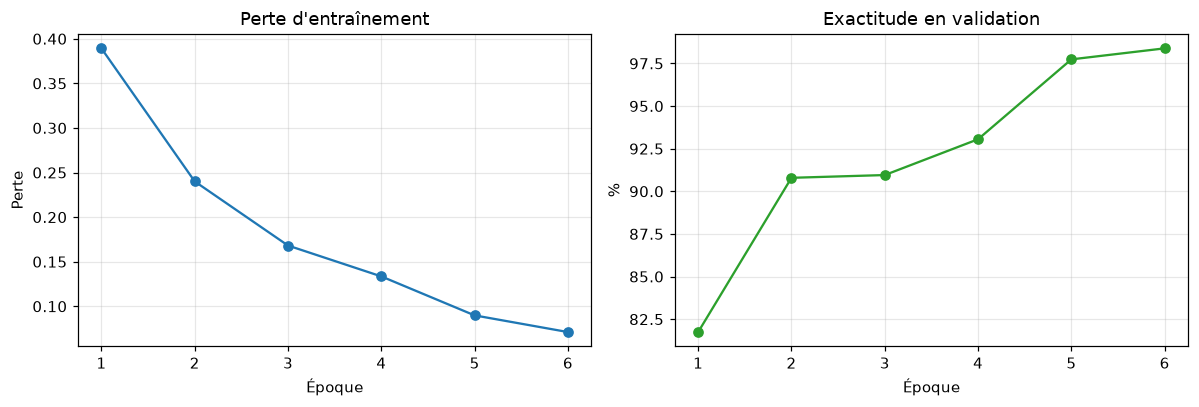

In [4]:
h = pd.DataFrame(historique)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(h["epoque"], h["perte"], marker="o")
ax1.set(title="Perte d'entraînement", xlabel="Époque", ylabel="Perte")
ax2.plot(h["epoque"], h["exactitude_validation"] * 100, marker="o", color="tab:green")
ax2.set(title="Exactitude en validation", xlabel="Époque", ylabel="%")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    ax.set_xticks(h["epoque"])
plt.tight_layout()
plt.show()

## 3. Évaluation sur le jeu de test

Le meilleur modèle est rechargé, puis évalué sur les images de test, jamais vues pendant l'entraînement.
La classe positive est **endommagé** : le rappel indique la part des pièces endommagées détectées,
la précision la part des alertes justifiées. Critères visés : rappel ≥ 90 % et précision ≥ 85 %.

In [5]:
sauvegarde = torch.load(CHEMIN_MODELE, map_location="cpu", weights_only=True)
modele.load_state_dict(sauvegarde["etat"])
modele.eval()
print(f"Modèle de l'époque {sauvegarde['epoque']} rechargé")

POSITIF = CLASSES.index("endommage")
vraies, predites, probas = [], [], []
with torch.no_grad():
    for x, y in chargeurs["test"]:
        p = torch.softmax(modele(x), dim=1)
        probas += p[:, POSITIF].tolist()
        predites += p.argmax(1).tolist()
        vraies += y.tolist()

test = pd.DataFrame({
    "fichier": [Path(chemin).name for chemin, _ in jeux["test"].samples],
    "chemin": [chemin for chemin, _ in jeux["test"].samples],
    "vraie": [CLASSES[v] for v in vraies],
    "predite": [CLASSES[p] for p in predites],
    "proba_endommage": probas,
})
test["source"] = test["fichier"].str.split("_").str[0]
test["correct"] = test["vraie"] == test["predite"]

def mesures(df):
    v = (df["vraie"] == "endommage").astype(int)
    p = (df["predite"] == "endommage").astype(int)
    return {"Images": len(df), "Exactitude": df["correct"].mean(),
            "Rappel (endommagé)": recall_score(v, p, zero_division=0),
            "Précision (endommagé)": precision_score(v, p, zero_division=0)}

resultats = pd.DataFrame({"Global": mesures(test),
                          **{f"Source : {s}": mesures(g) for s, g in test.groupby("source")}}).T
resultats["Images"] = resultats["Images"].astype(int)

rappel, precision = resultats.loc["Global", "Rappel (endommagé)"], resultats.loc["Global", "Précision (endommagé)"]
print(f"Rappel    : {rappel:.1%}  (critère ≥ 90 %) → {'ATTEINT' if rappel >= 0.90 else 'NON ATTEINT'}")
print(f"Précision : {precision:.1%}  (critère ≥ 85 %) → {'ATTEINT' if precision >= 0.85 else 'NON ATTEINT'}")

_ = (DOSSIER_RESULTATS / "v2_metriques_test.json").write_text(resultats.to_json(orient="index", indent=2), encoding="utf-8")
resultats.style.format({"Exactitude": "{:.1%}", "Rappel (endommagé)": "{:.1%}", "Précision (endommagé)": "{:.1%}"})

Modèle de l'époque 6 rechargé
Rappel    : 97.2%  (critère ≥ 90 %) → ATTEINT
Précision : 99.1%  (critère ≥ 85 %) → ATTEINT


,Images,Exactitude,Rappel (endommagé),Précision (endommagé)
Global,680,98.1%,97.2%,99.1%
Source : casting,195,99.5%,99.1%,100.0%
Source : pneus,274,96.0%,94.7%,97.9%
Source : roulements,211,99.5%,98.8%,100.0%


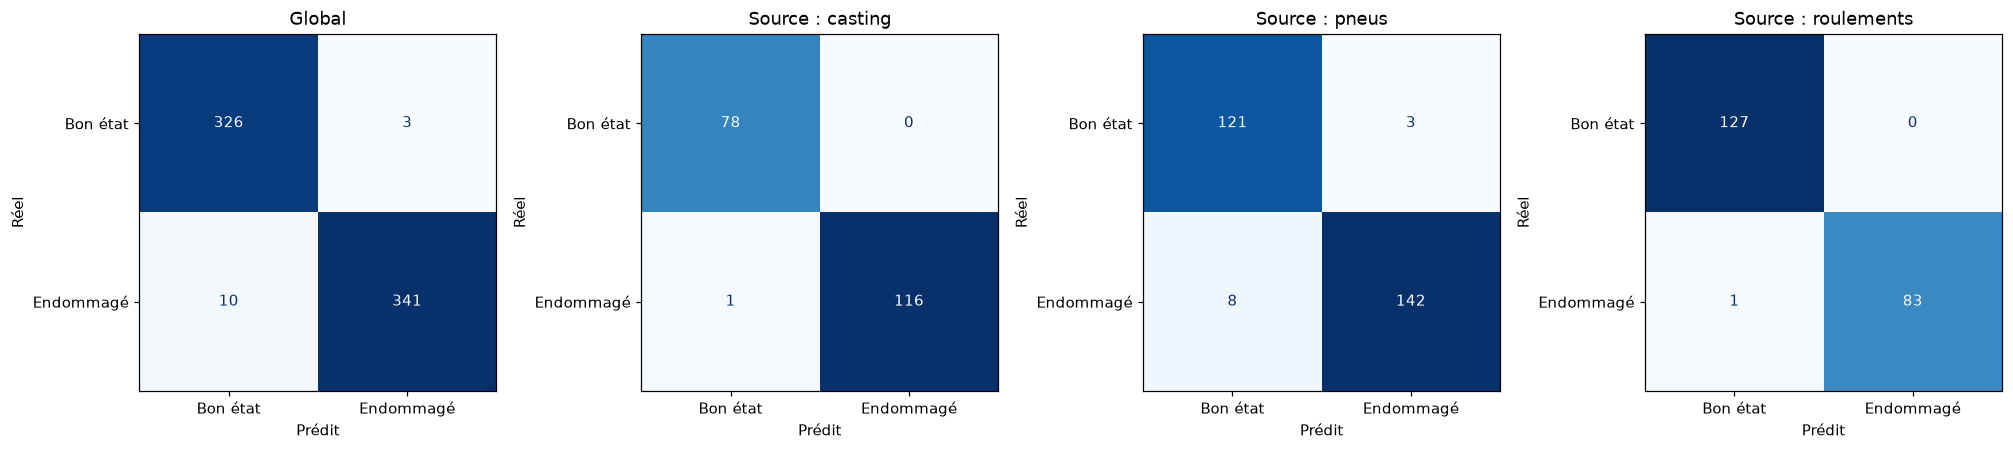

In [6]:
panneaux = [("Global", test)] + [(f"Source : {s}", g) for s, g in test.groupby("source")]
fig, axes = plt.subplots(1, len(panneaux), figsize=(4.6 * len(panneaux), 4.2))
for ax, (titre, df) in zip(axes, panneaux):
    matrice = confusion_matrix(df["vraie"], df["predite"], labels=CLASSES)
    ConfusionMatrixDisplay(matrice, display_labels=[NOMS[c] for c in CLASSES]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set(title=titre, xlabel="Prédit", ylabel="Réel")
plt.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "v2_matrices_confusion.png", dpi=150)
plt.show()

## 4. Erreurs du modèle

Les images de test mal classées (12 au maximum), avec la probabilité « endommagé » donnée par le modèle.

13 erreur(s) sur 680 images de test
source      vraie    
casting     endommage    1
pneus       bon_etat     3
            endommage    8
roulements  endommage    1


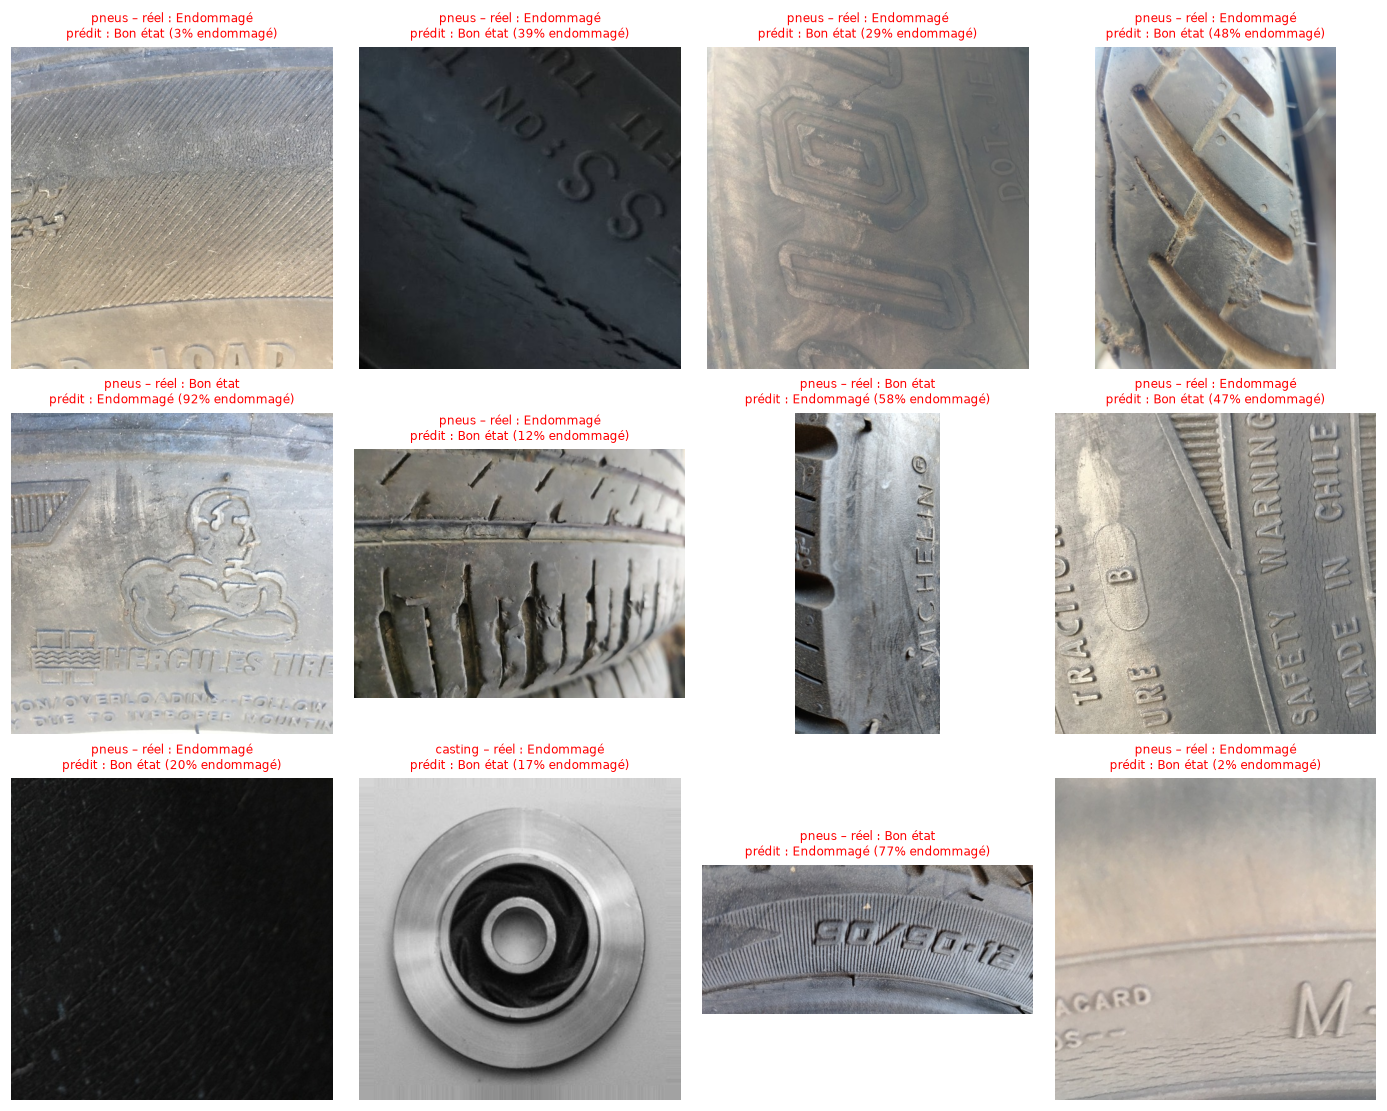

In [7]:
erreurs = test[~test["correct"]]
print(f"{len(erreurs)} erreur(s) sur {len(test)} images de test")
print(erreurs.groupby(["source", "vraie"]).size().rename("erreurs").to_string())
if len(erreurs):
    montrees = erreurs.sample(min(12, len(erreurs)), random_state=0)
    colonnes = min(4, len(montrees))
    lignes_fig = int(np.ceil(len(montrees) / colonnes))
    fig, axes = plt.subplots(lignes_fig, colonnes, figsize=(3.2 * colonnes, 3.4 * lignes_fig), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, e) in zip(axes.flat, montrees.iterrows()):
        ax.imshow(Image.open(e["chemin"]))
        ax.set_title(f"{e['source']} – réel : {NOMS[e['vraie']]}\nprédit : {NOMS[e['predite']]} "
                     f"({e['proba_endommage']:.0%} endommagé)", fontsize=8, color="red")
    plt.tight_layout()
    plt.show()

## 5. Où le modèle regarde-t-il ? (Grad-CAM)

Pour chaque source, une image en bon état et une image endommagée du jeu de test.
On vérifie que le modèle regarde la pièce et ses défauts, plutôt que le fond de l'image.

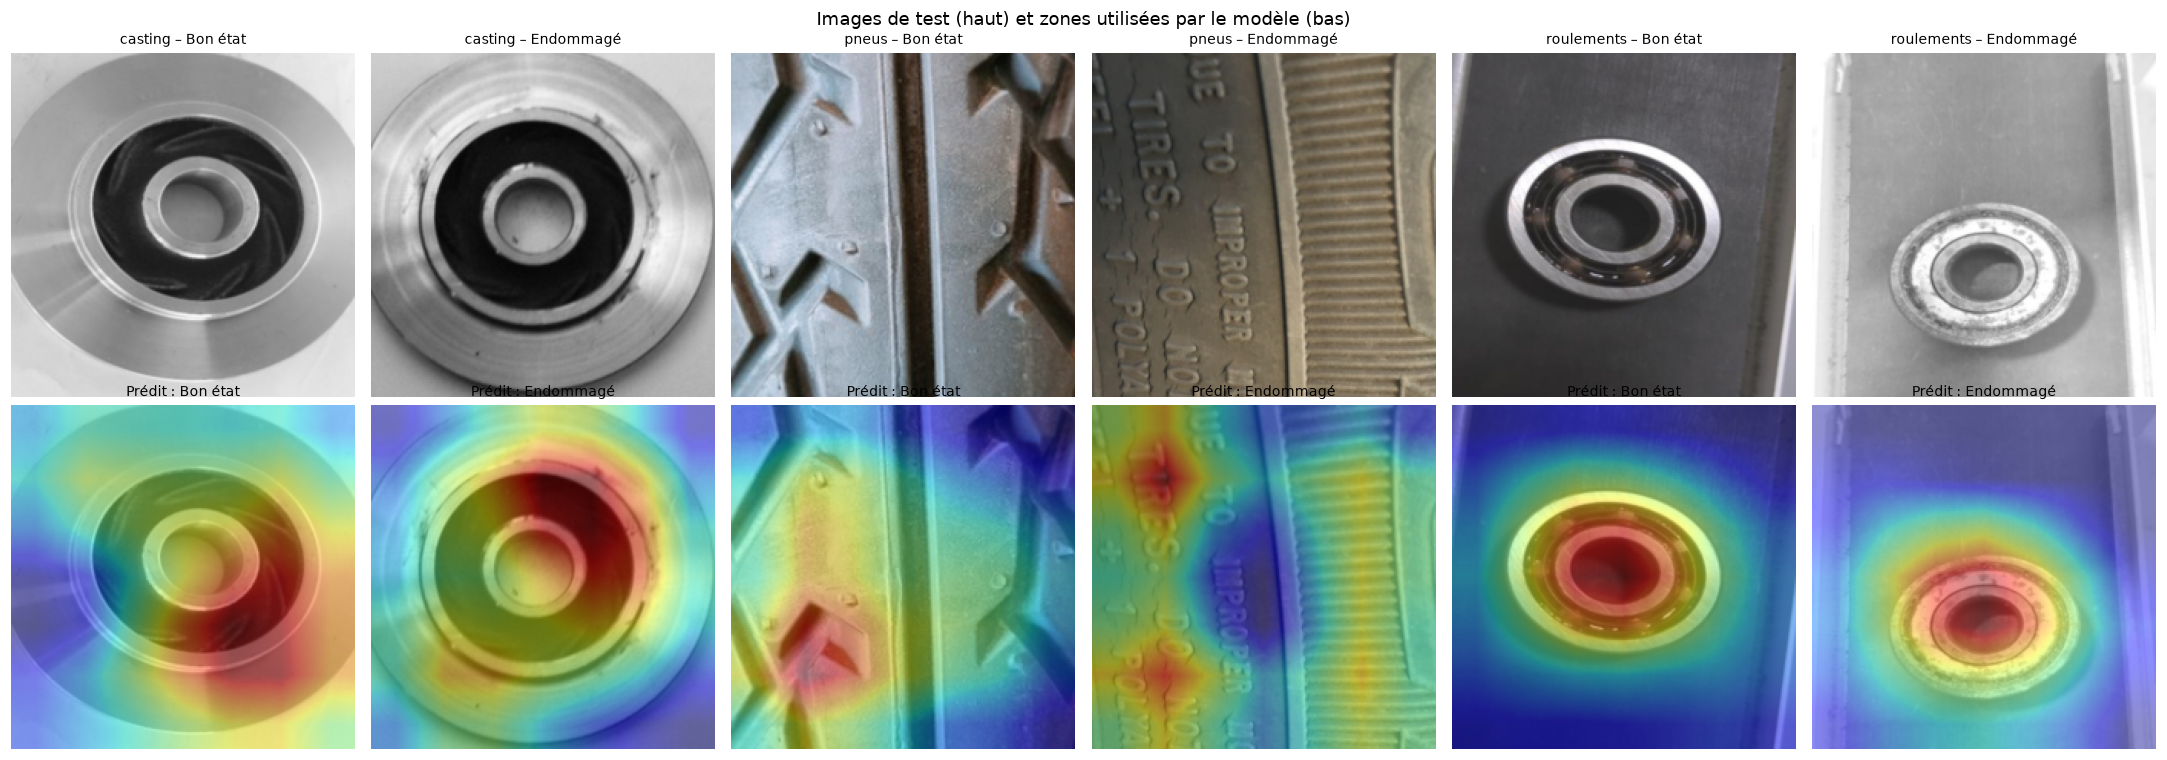

In [8]:
def grad_cam(tenseur):
    sauvegarde = {}
    def capturer(module, entree, sortie):
        sauvegarde["a"] = sortie
        sortie.register_hook(lambda g: sauvegarde.__setitem__("g", g))
    crochet = modele.layer4.register_forward_hook(capturer)
    sortie = modele(tenseur)
    crochet.remove()
    classe = sortie.argmax(1).item()
    modele.zero_grad()
    sortie[0, classe].backward()
    poids = sauvegarde["g"].mean(dim=(2, 3), keepdim=True)
    carte = F.relu((poids * sauvegarde["a"]).sum(dim=1, keepdim=True))
    carte = F.interpolate(carte, size=tenseur.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    return (carte / (carte.max() + 1e-8)).detach().numpy(), classe

def vue_modele(image):
    # Même cadrage que transfo_evaluation, sans normalisation, pour l'affichage
    return transforms.CenterCrop(224)(transforms.Resize(256)(image))

choix = [g.sample(1, random_state=3).iloc[0] for _, g in test.groupby(["source", "vraie"])]
fig, axes = plt.subplots(2, len(choix), figsize=(3.3 * len(choix), 7), squeeze=False)
for j, e in enumerate(choix):
    image = Image.open(e["chemin"]).convert("RGB")
    carte, classe = grad_cam(transfo_evaluation(image).unsqueeze(0))
    axes[0, j].imshow(vue_modele(image))
    axes[0, j].set_title(f"{e['source']} – {NOMS[e['vraie']]}", fontsize=9)
    axes[1, j].imshow(vue_modele(image))
    axes[1, j].imshow(carte, cmap="jet", alpha=0.45)
    axes[1, j].set_title(f"Prédit : {NOMS[CLASSES[classe]]}", fontsize=9)
    for ax in axes[:, j]:
        ax.axis("off")
fig.suptitle("Images de test (haut) et zones utilisées par le modèle (bas)", fontsize=12)
plt.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "v2_grad_cam.png", dpi=130)
plt.show()

## 6. Test sur les photos réelles

Les photos de `data/photos_reelles/` : le dossier `aucun` correspond à une pièce en **bon état**,
tous les autres dossiers (`rayures`, `piqures`…) à une pièce **endommagée**.

8 photo(s) trouvée(s)
Photos correctement classées : 5/8


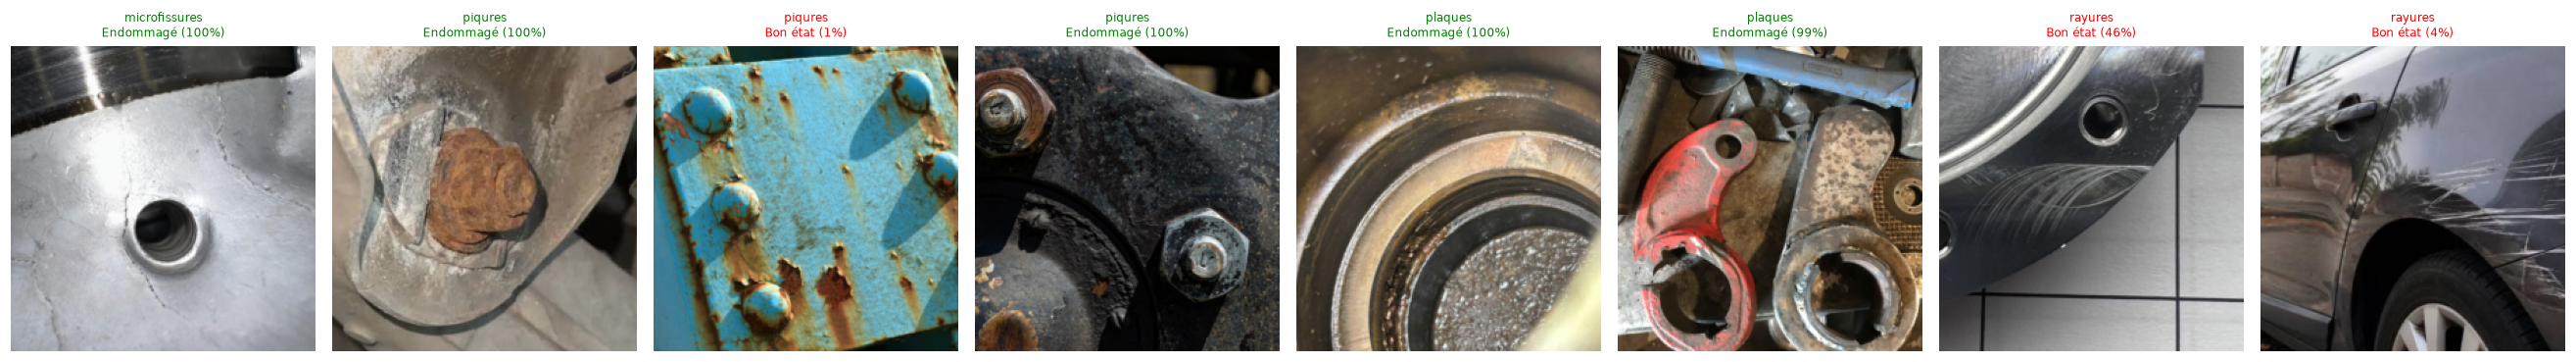

Photo,Dossier,Attendu,Prédit,Proba endommagé,Correct
m13aeakekqmb1.jpg,microfissures,Endommagé,Endommagé,100%,True
boulon rouiller.jpg,piqures,Endommagé,Endommagé,100%,True
rouille.jpg,piqures,Endommagé,Bon état,1%,False
rusted-bolt.jpg,piqures,Endommagé,Endommagé,100%,True
IMG_20261030_005430.jpg,plaques,Endommagé,Endommagé,100%,True
IMG_20261030_005441.jpg,plaques,Endommagé,Endommagé,99%,True
pb2zod9hjrje1.jpg,rayures,Endommagé,Bon état,46%,False
Rayure.jpg,rayures,Endommagé,Bon état,4%,False


In [9]:
DOSSIER_PHOTOS = RACINE / "data" / "photos_reelles"
photos = [p for p in sorted(DOSSIER_PHOTOS.rglob("*")) if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
print(f"{len(photos)} photo(s) trouvée(s)")

lignes = []
for chemin in photos:
    dossier = chemin.parent.name if chemin.parent != DOSSIER_PHOTOS else "inconnu"
    attendu = "bon_etat" if dossier == "aucun" else ("endommage" if dossier != "inconnu" else None)
    image = ImageOps.exif_transpose(Image.open(chemin)).convert("RGB")
    with torch.no_grad():
        p = torch.softmax(modele(transfo_evaluation(image).unsqueeze(0)), dim=1)[0, POSITIF].item()
    predit = "endommage" if p >= 0.5 else "bon_etat"
    lignes.append({"Photo": chemin.name, "Dossier": dossier, "Attendu": NOMS.get(attendu, "?"),
                   "Prédit": NOMS[predit], "Proba endommagé": p, "Correct": (predit == attendu) if attendu else None,
                   "chemin": chemin})
reelles = pd.DataFrame(lignes)

if len(reelles):
    evaluees = reelles.dropna(subset=["Correct"])
    print(f"Photos correctement classées : {int(evaluees['Correct'].sum())}/{len(evaluees)}")
    colonnes = min(8, len(reelles))
    lignes_fig = int(np.ceil(len(reelles) / colonnes))
    fig, axes = plt.subplots(lignes_fig, colonnes, figsize=(3 * colonnes, 3.6 * lignes_fig), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, r) in zip(axes.flat, reelles.iterrows()):
        ax.imshow(vue_modele(ImageOps.exif_transpose(Image.open(r["chemin"])).convert("RGB")))
        couleur = "black" if r["Correct"] is None else ("green" if r["Correct"] else "red")
        ax.set_title(f"{r['Dossier']}\n{r['Prédit']} ({r['Proba endommagé']:.0%})", fontsize=8, color=couleur)
    plt.tight_layout()
    fig.savefig(DOSSIER_RESULTATS / "v2_photos_reelles.png", dpi=130)
    plt.show()
    display(reelles.drop(columns="chemin").style.format({"Proba endommagé": "{:.0%}"}).hide(axis="index"))